# Poisson interaction range를 바꿀 때 KNEEP의 EP는 어떻게 반응하는가?

LRAMB의 Poisson kernel 길이 \(\ell=1,2,4,8\)을 **동역학 자체에서** 바꾸고 각 조건에서 새 trajectory를 생성한다. 결합 세기 \(g=0.35\), 나머지 AMB 물리 파라미터와 관측/학습 절차는 고정한다. 관측된 field movie만으로 기존 ShellForce KNEEP를 독립적으로 학습하고, 사용하지 않은 test trajectory에서 반응을 비교한다.

1. 데이터셋 생성 → 2. 저장된 데이터로 학습 → 3. 평가 배열 계산 → 4. cell 안에서 figure 생성·표시.
시뮬레이션과 학습은 별도 cell이며, 저장한 PNG를 읽어 표시하지 않는다. 데이터·checkpoint·평가 수치만 캐시한다.

기본 `demo`는 실험 실행을 위한 시작점이다. `quick`은 연결 확인용이며 물리적 결론을 내리는 설정이 아니다. `reference`는 LRAMB 원래 시간 프로토콜에 맞춘 더 큰 실험이다. **EP가 \(\ell\)에 대해 단조 증가한다고 가정하지 않는다.**

기본 demo는 CPU에서 학습만 수 시간이 걸릴 수 있다. 빠른 실행 확인에는 quick을 선택한다. 이 notebook에 포함되는 실행 출력은 quick 연결 점검 결과이며, 수렴한 range sweep 결과가 아니다.


## LRAMB에서 가져온 정의와 비교할 양

[LRAMB model.py](../../LRAMB/lramb/model.py)의 보존적 Active Model B를 사용한다.
\[
d\phi=M\nabla^2\{\mu_C+\lambda|\nabla\phi|^2\}dt+\text{conserved noise},\qquad
K_\ell(q)=e^{-\ell q}\;(q>0),\quad K_\ell(0)=0,
\]
\[
q^2=\sum_{\alpha=x,y}\left[\frac{2}{dx}\sin(k_\alpha dx/2)\right]^2,\qquad
\mu_K=gK_\ell *\phi .
\]

[LRAMB range_sweep.py](../../LRAMB/lramb/range_sweep.py)처럼 \(\ell\)별로 새 dynamics를 적분한다. 같은 역할·trajectory 번호는 \(\ell\) 사이에서 초기조건과 noise seed를 공유하며, train / validation / test 역할 사이에는 별도 seed를 쓴다. \(\ell\)이 커지면 공간적으로 퍼진 kernel이 되지만, 고정된 \(g\)에서도 각 nonzero Fourier mode의 세기는 약해진다. 추가 \(\ell\) 의존 정규화는 하지 않는다. zero mode 제거 때문에 실제 실공간 weights는 부호가 있고 합이 0이다.

[LRAMB ep_ranges.py](../../LRAMB/lramb/ep_ranges.py)의 원칙에 따라 signed EP를 먼저 합한 뒤 변동을 계산한다. 이 실험의 reference shell은 KNEEP의 정사각형 branch와 비교하기 위해 **주기적 최소영상 Chebyshev 거리**로 다시 묶었다. LRAMB 원래 Euclidean shell과는 거리 좌표가 다르다.


In [1]:
%matplotlib inline
from pathlib import Path
from dataclasses import asdict, replace
import os
import sys

def find_kneep_root(start: Path) -> Path:
    for parent in (start, *start.parents):
        for candidate in (parent, parent / "KNEEP"):
            if (candidate / "shell_force.py").is_file() and (candidate / "models").is_dir():
                return candidate.resolve()
    raise FileNotFoundError("KNEEP 또는 그 상위 workspace에서 notebook을 실행하세요.")

KNEEP_ROOT = find_kneep_root(Path.cwd())
LRAMB_ROOT = KNEEP_ROOT.parent / "LRAMB"
sys.path.insert(0, str(KNEEP_ROOT)) if str(KNEEP_ROOT) not in sys.path else None

import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from models.lramb_poisson import (
    DatasetConfig, dataset_preset, generate_datasets, read_manifest, load_dataset,
)
from scripts.lramb_poisson_range import (
    FitConfig, fit_preset, train_sweep, evaluate_sweep,
)
from utils.poisson_range_plots import (
    plot_cumulative_ep, plot_time_averaged_ep, plot_ep_spectrum,
    plot_temporal_spectrum, plot_range_response, plot_training_history,
    plot_kernel_diagnostics,
)

torch.set_num_threads(1)
plt.rcParams.update({"figure.dpi": 105, "axes.titlesize": 10, "axes.labelsize": 9})
print("KNEEP:", KNEEP_ROOT)
print("LRAMB:", LRAMB_ROOT)
print("CUDA available:", torch.cuda.is_available())


KNEEP: C:\Users\ldh04\OneDrive\문서\CANONEQal\repos\KNEEP
LRAMB: C:\Users\ldh04\OneDrive\문서\CANONEQal\repos\LRAMB
CUDA available: False


## 설정: demo / quick / reference

| profile | 격자 | burn steps | production steps | 저장 간격 (steps) | train / val / test | 학습 seed 수 | iterations | 학습 최대 shell |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| quick | 8² | 16 | 64 | 1 | 2 / 1 / 2 | 2 | 4 | 2 |
| demo (기본) | 32² | 4,000 | 8,192 | 8 | 4 / 2 / 3 | 3 | 2,000 | 8 |
| reference | 64² | 40,000 | 64,000 | 40 | 4 / 2 / 3 | 5 | 5,000 | 8 |

모든 profile에서 \(dt=0.01,\;dx=1,\;a=-1,\;b=1,\;\kappa=1,\;\lambda=0.8,\;D=0.05,\;\bar\phi=-0.2,\;M=1,\;g=0.35\).
학습 모델과 receptive radius는 해당 profile의 모든 \(\ell\)에서 동일하다. 기존 periodic convolution에서 반대편 이웃을 중복 세지 않도록 학습 radius는 \(n/2\)보다 작게 둔다. 물리 reference에는 \(n/2\)까지 모든 shell이 포함된다.

데이터 생성은 기본 CPU, 학습/평가는 CUDA가 있으면 CUDA를 사용한다. CPU에서도 실행할 수 있다. 아래 설정을 바꾼 경우에는 새로운 결과 폴더를 권장한다. 캐시가 다른 설정이면 재사용을 거부한다. 필요할 때 각 단계의 FORCE flag를 직접 변경한다.


In [2]:
# 저장된 notebook의 기본값은 demo. 자동 점검에서는 환경변수로 quick을 선택할 수 있다.
PROFILE = os.environ.get("KNEEP_POISSON_PROFILE", "demo")
DATA_DEVICE = os.environ.get("KNEEP_POISSON_DATA_DEVICE", "cpu")
FIT_DEVICE = os.environ.get("KNEEP_POISSON_FIT_DEVICE", "auto")
OUTPUT_DIR = Path(os.environ.get(
    "KNEEP_POISSON_OUTPUT_DIR",
    str(KNEEP_ROOT / "results" / "lramb_poisson_range" / PROFILE),
)).expanduser().resolve()

DATA_CONFIG = dataset_preset(PROFILE)
FIT_CONFIG = fit_preset(PROFILE)
assert tuple(DATA_CONFIG.ells) == (1.0, 2.0, 4.0, 8.0)
assert DATA_CONFIG.strength == 0.35
assert FIT_CONFIG.max_distance < DATA_CONFIG.n / 2

FORCE_GENERATE = False
FORCE_TRAIN = False
FORCE_EVALUATE = False

display(Markdown(f"**Profile:** {PROFILE} · **결과 폴더:** `{OUTPUT_DIR}`"))
display({"dataset": DATA_CONFIG.to_dict(), "fit": asdict(FIT_CONFIG)})
print(f"저장된 pair 간격 = {DATA_CONFIG.interval:g}, trajectory당 production 시간 = {DATA_CONFIG.duration:g}")


**Profile:** quick · **결과 폴더:** `C:\Users\ldh04\OneDrive\문서\CANONEQal\repos\KNEEP\results\lramb_poisson_range\quick`

{'dataset': {'ells': [1.0, 2.0, 4.0, 8.0],
  'n': 8,
  'dx': 1.0,
  'dt': 0.01,
  'a': -1.0,
  'b': 1.0,
  'kappa': 1.0,
  'lam': 0.8,
  'mobility': 1.0,
  'D': 0.05,
  'mean': -0.2,
  'strength': 0.35,
  'burn_steps': 16,
  'production_steps': 64,
  'sample_every': 1,
  'blocks': 4,
  'train_trajectories': 2,
  'validation_trajectories': 1,
  'test_trajectories': 2,
  'base_seed': 17,
  'initial_mode': 'stripe'},
 'fit': {'max_distance': 2,
  'hidden_channels': 4,
  'hidden_layers': 1,
  'repeats': 2,
  'base_seed': 1701,
  'activation': 'elu',
  'training': {'alpha': -0.5,
   'iterations': 4,
   'train_batch_size': 4,
   'validation_batch_size': 16,
   'prediction_batch_size': 16,
   'learning_rate': 0.001,
   'weight_decay': 1e-05,
   'gradient_clip': 1.0,
   'validate_every': 2,
   'train_fraction': 0.8}}}

저장된 pair 간격 = 0.01, trajectory당 production 시간 = 0.64


## 1. 데이터셋 생성 — 학습하지 않음

각 \(\ell\)에서 독립된 train / validation / test trajectory를 LRAMB solver로 생성한다. 정규화 통계는 이후 train에서만 구하고, validation은 checkpoint 선택에만 쓴다. reference EP는 학습 loss에 넣지 않는다.

Reference medium EP는 **저장된 frame 차이가 아니라 모든 solver step**에서 midpoint chemical potential을 사용해 누적한다.
\[
\Delta S_{\rm med}=-\frac{dx^2}{D}\sum_x
  (\mu_{\rm local,C}+\mu_K+\mu_{\rm active})_{x,\rm mid}\,\Delta\phi_x.
\]
KNEEP 입력 frame과 reference interval은 시간상 일치하지만, `sample_every > 1`이면 KNEEP는 그 사이의 path를 관측하지 못한다. 충분한 burn-in과 stationary 여부를 아래 diagnostic으로 확인해야 한다.


In [3]:
# 이 cell은 dataset 파일만 생성한다. 학습 단계와 분리되어 있다.
dataset_manifest = generate_datasets(
    DATA_CONFIG,
    OUTPUT_DIR,
    lramb_root=LRAMB_ROOT,
    device=DATA_DEVICE,
    progress=True,
    force=FORCE_GENERATE,
)
display({
    "dataset_complete": read_manifest(OUTPUT_DIR)["complete"],
    "ells": DATA_CONFIG.ells,
    "roles": ("train", "validation", "test"),
    "dataset_file": str(OUTPUT_DIR / "dataset.json"),
})


ell=1, train: using matching dataset


ell=1, validation: using matching dataset


ell=1, test: using matching dataset


ell=2, train: using matching dataset


ell=2, validation: using matching dataset


ell=2, test: using matching dataset


... (3 outputs left out)

ell=8, train: using matching dataset


ell=8, validation: using matching dataset


ell=8, test: using matching dataset


{'dataset_complete': True,
 'ells': (1.0, 2.0, 4.0, 8.0),
 'roles': ('train', 'validation', 'test'),
 'dataset_file': 'C:\\Users\\ldh04\\OneDrive\\문서\\CANONEQal\\repos\\KNEEP\\results\\lramb_poisson_range\\quick\\dataset.json'}

## 2. 학습 — 저장된 train / validation만 읽음

기존 [ShellForceKNEEP2D](../shell_force.py)와 [training.py](../utils/training.py)를 사용한다. \(\ell\)마다 같은 모델 용량과 radius로 학습하고, 각 학습 seed에서 validation loss가 가장 좋은 checkpoint를 선택한다. test movie는 여기서 읽지 않는다.

반경 \(r>0\) branch는 중심을 제외한 해당 정사각형 shell의 이웃만 입력받으며, 모든 branch의 기여는 가산적으로 합쳐진다. 이 제한된 force 함수족은 중심과 이웃의 교차항을 포함하는 scalar AMB의 모든 힘을 정확히 표현하지 못할 수 있다. 이 실험은 **기존 KNEEP가 range 변화에 어떻게 반응하는지**를 측정하며 exact recovery를 보장하지 않는다.


In [4]:
# 이 cell은 dataset을 생성하지 않는다. 이미 저장된 train/validation만 사용한다.
training_manifest = train_sweep(
    OUTPUT_DIR,
    FIT_CONFIG,
    device=FIT_DEVICE,
    progress=True,
    force=FORCE_TRAIN,
)
display({
    "training_complete": training_manifest["complete"],
    "repeats": FIT_CONFIG.repeats,
    "max_distance": FIT_CONFIG.max_distance,
    "checkpoint_directory": str(OUTPUT_DIR / "checkpoints"),
})


ell=1, repeat=1: reusing completed fit


ell=1, repeat=2: reusing completed fit


ell=2, repeat=1: reusing completed fit


ell=2, repeat=2: reusing completed fit


ell=4, repeat=1: reusing completed fit


ell=4, repeat=2: reusing completed fit


ell=8, repeat=1: reusing completed fit


ell=8, repeat=2: reusing completed fit


{'training_complete': True,
 'repeats': 2,
 'max_distance': 2,
 'checkpoint_directory': 'C:\\Users\\ldh04\\OneDrive\\문서\\CANONEQal\\repos\\KNEEP\\results\\lramb_poisson_range\\quick\\checkpoints'}

## 3. Held-out 평가와 단위 확인

KNEEP가 반환하는 spatial mean score 자체가 전체 field의 learned EP increment이다. 이를 다시 격자 수로 곱하지 않는다. KNEEP raw map은 \(n^2\,\Delta t_{\rm obs}\)로 나눠 **site별 rate 기여량**으로 바꾼다. 따라서 map의 공간 합은 global mean rate와 일치한다.

반면 LRAMB reference map은 rate **density**이므로 공간 적분할 때 \(dx^2\)를 곱한다. 아래 map figure도 비교 단위를 맞추기 위해 reference에 \(dx^2\)를 적용한다.

두 reference gauge는 다르다. KNEEP의 인접 관측 pair 기반 time-arrow estimate는 stationary path EP를 겨냥하며, 표시한 medium reference에는 stochastic system entropy boundary가 없다. 유한 observation cadence, 유한 데이터, 모델 용량, 비정상성 때문에 cumulative curve나 map이 일치할 필요가 없다. 정확히 가역적인 stationary pair에서는 KNEEP의 EP가 0이어도 medium EP의 경계 변동은 남을 수 있다.


In [5]:
records = evaluate_sweep(
    OUTPUT_DIR,
    device=FIT_DEVICE,
    batch_size=FIT_CONFIG.training.prediction_batch_size,
    force=FORCE_EVALUATE,
)

# 축: predicted [fit seed, independent test trajectory, interval, learned branch]
# reference [independent test trajectory, interval, physical component]
for record in records:
    predicted_rate = record["predicted_increment"].sum(-1).mean(-1) / record["interval"]
    predicted_map_rate = record["predicted_map"].sum((-3, -2, -1))
    reference_rate = record["reference_increment"].sum(-1).mean(-1) / record["interval"]
    reference_map_rate = record["reference_map"].sum((-3, -2, -1)) * record["dx"]**2
    np.testing.assert_allclose(predicted_map_rate, predicted_rate, rtol=2e-5, atol=1e-7)
    np.testing.assert_allclose(reference_map_rate, reference_rate, rtol=2e-5, atol=1e-7)
    print(f"ell={record['ell']:g}: predicted {record['predicted_increment'].shape}, "
          f"reference {record['reference_increment'].shape}; map sum consistency OK")


ell=1: predicted (2, 2, 64, 3), reference (2, 64, 3); map sum consistency OK
ell=2: predicted (2, 2, 64, 3), reference (2, 64, 3); map sum consistency OK
ell=4: predicted (2, 2, 64, 3), reference (2, 64, 3); map sum consistency OK
ell=8: predicted (2, 2, 64, 3), reference (2, 64, 3); map sum consistency OK


## 먼저 stationarity와 학습 상태 확인

아래는 test trajectory의 field variance, conservative energy, medium / active EP를 production 시간의 네 구간으로 나눠 본다. 점과 선은 독립 trajectory의 평균이며 confidence interval이 아니다. 구간별 systematic drift가 크면 burn-in과 production을 늘려 새 데이터셋을 생성한다. 평평해 보이는 것만으로 stationarity를 증명할 수는 없다.

회색 band와 파란 band는 이후 figure에서 각각 **독립 test trajectory 간 표준편차**와 **동일 데이터에서 학습 seed만 바꾼 표준편차**를 뜻한다. temporal sample은 상관되어 있으므로 iid 오차나 95% confidence interval로 해석하지 않는다.


ell=1: max mean-field drift = 8.33e-17; active quarter rates = [28.9894 19.5661 20.8978 11.1924]
ell=2: max mean-field drift = 8.33e-17; active quarter rates = [29.646  20.585  22.0313 11.8545]
ell=4: max mean-field drift = 8.33e-17; active quarter rates = [29.8644 21.0229 22.6052 12.0655]
ell=8: max mean-field drift = 1.11e-16; active quarter rates = [29.892  21.0965 22.7277 12.0809]


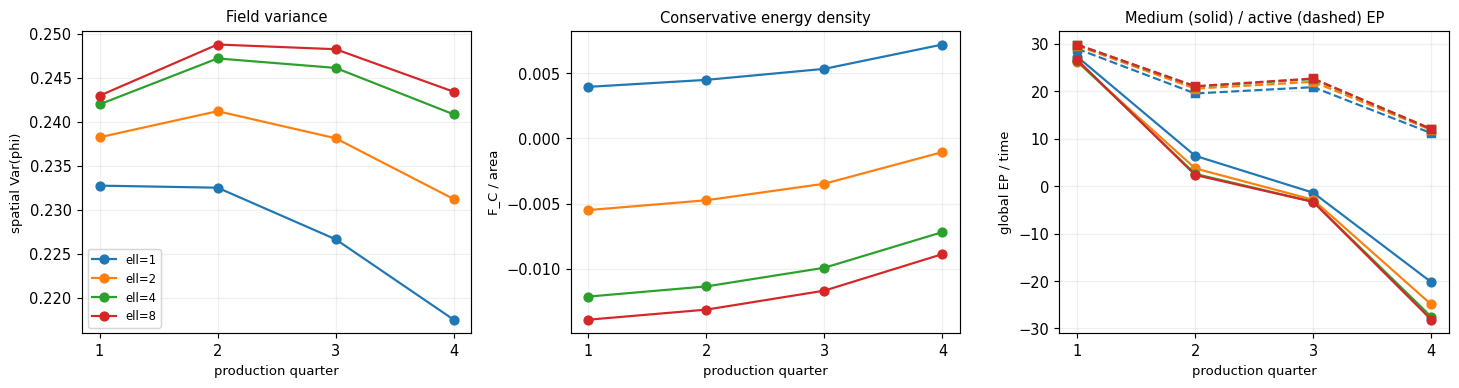

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for record in records:
    ell = record["ell"]
    diagnostics = record["diagnostics"]
    variance = np.asarray(diagnostics["variance"])
    energy = np.asarray(diagnostics["energy"]).sum(-1)
    mass = np.asarray(diagnostics["mass"])
    area = (record["fields"].shape[-1] * record["dx"])**2
    medium = record["reference_increment"].sum(-1) / record["interval"]
    active = record["reference_increment"][..., 2] / record["interval"]
    # State statistics use interval endpoint frames; all arrays retain trajectory boundaries.
    variance_quarters = np.stack([x.mean(-1) for x in np.array_split(variance[:, 1:], 4, axis=1)], axis=-1)
    energy_quarters = np.stack([x.mean(-1) for x in np.array_split(energy[:, 1:], 4, axis=1)], axis=-1) / area
    medium_quarters = np.stack([x.mean(-1) for x in np.array_split(medium, 4, axis=1)], axis=-1)
    active_quarters = np.stack([x.mean(-1) for x in np.array_split(active, 4, axis=1)], axis=-1)
    quarter = np.arange(1, 5)
    line, = axes[0].plot(quarter, variance_quarters.mean(0), "o-", label=f"ell={ell:g}")
    color = line.get_color()
    axes[1].plot(quarter, energy_quarters.mean(0), "o-", color=color)
    axes[2].plot(quarter, medium_quarters.mean(0), "o-", color=color)
    axes[2].plot(quarter, active_quarters.mean(0), "s--", color=color)
    mass_error = np.max(np.abs(mass - mass[:, :1]))
    print(f"ell={ell:g}: max mean-field drift = {mass_error:.2e}; "
          f"active quarter rates = {np.round(active_quarters.mean(0), 4)}")
axes[0].set(title="Field variance", ylabel="spatial Var(phi)")
axes[1].set(title="Conservative energy density", ylabel="F_C / area")
axes[2].set(title="Medium (solid) / active (dashed) EP", ylabel="global EP / time")
axes[0].legend(fontsize=8)
for ax in axes:
    ax.set_xlabel("production quarter")
    ax.set_xticks(np.arange(1, 5))
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()


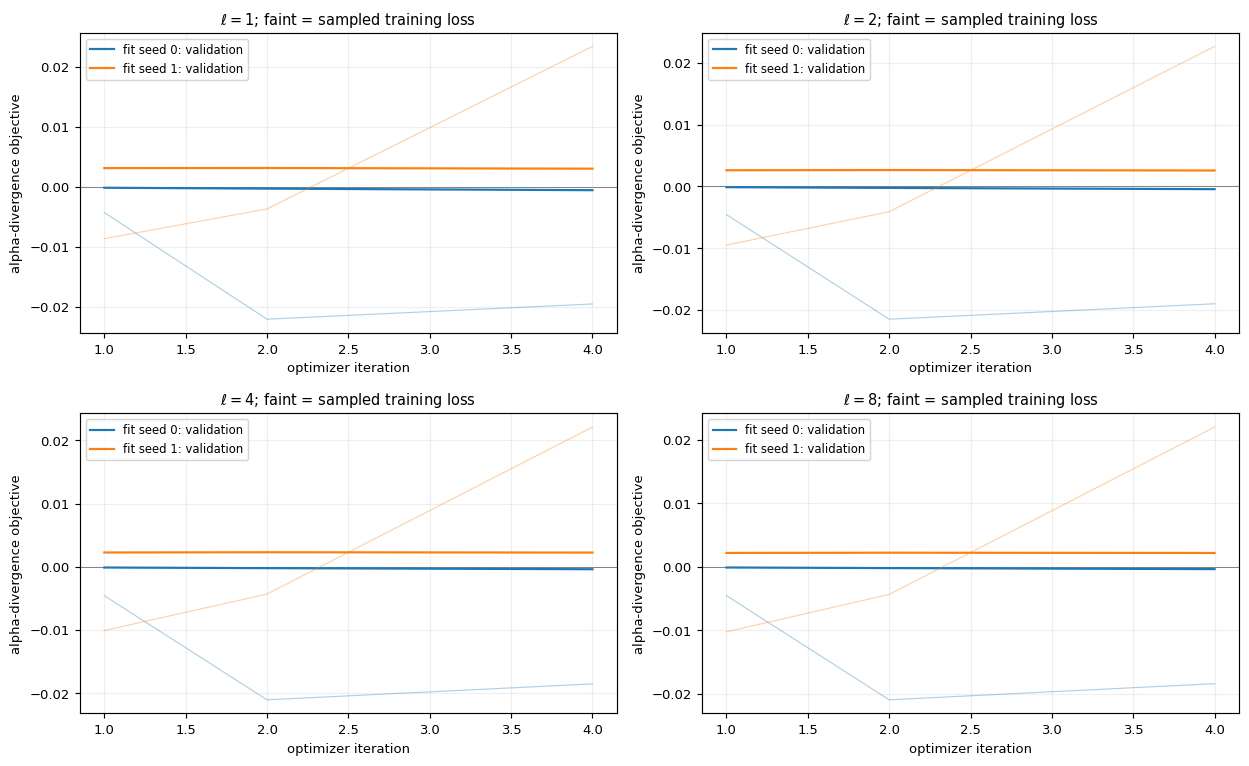

In [7]:
fig = plot_training_history(records)
plt.show()


## 실제 바뀐 Poisson kernel 확인

사용한 실공간 weights와 Fourier multiplier를 직접 그린다. \(K(0)=0\)이라 signed weights의 합은 0이다. 부호가 있는 kernel을 확률 분포처럼 정규화하지 않는다. 후속 range summary의 tail fraction은 \(\sum_x|w_x|\)에 대한 절댓값 비율이며, signed kernel 자체나 EP의 exact interaction range를 뜻하지 않는다.


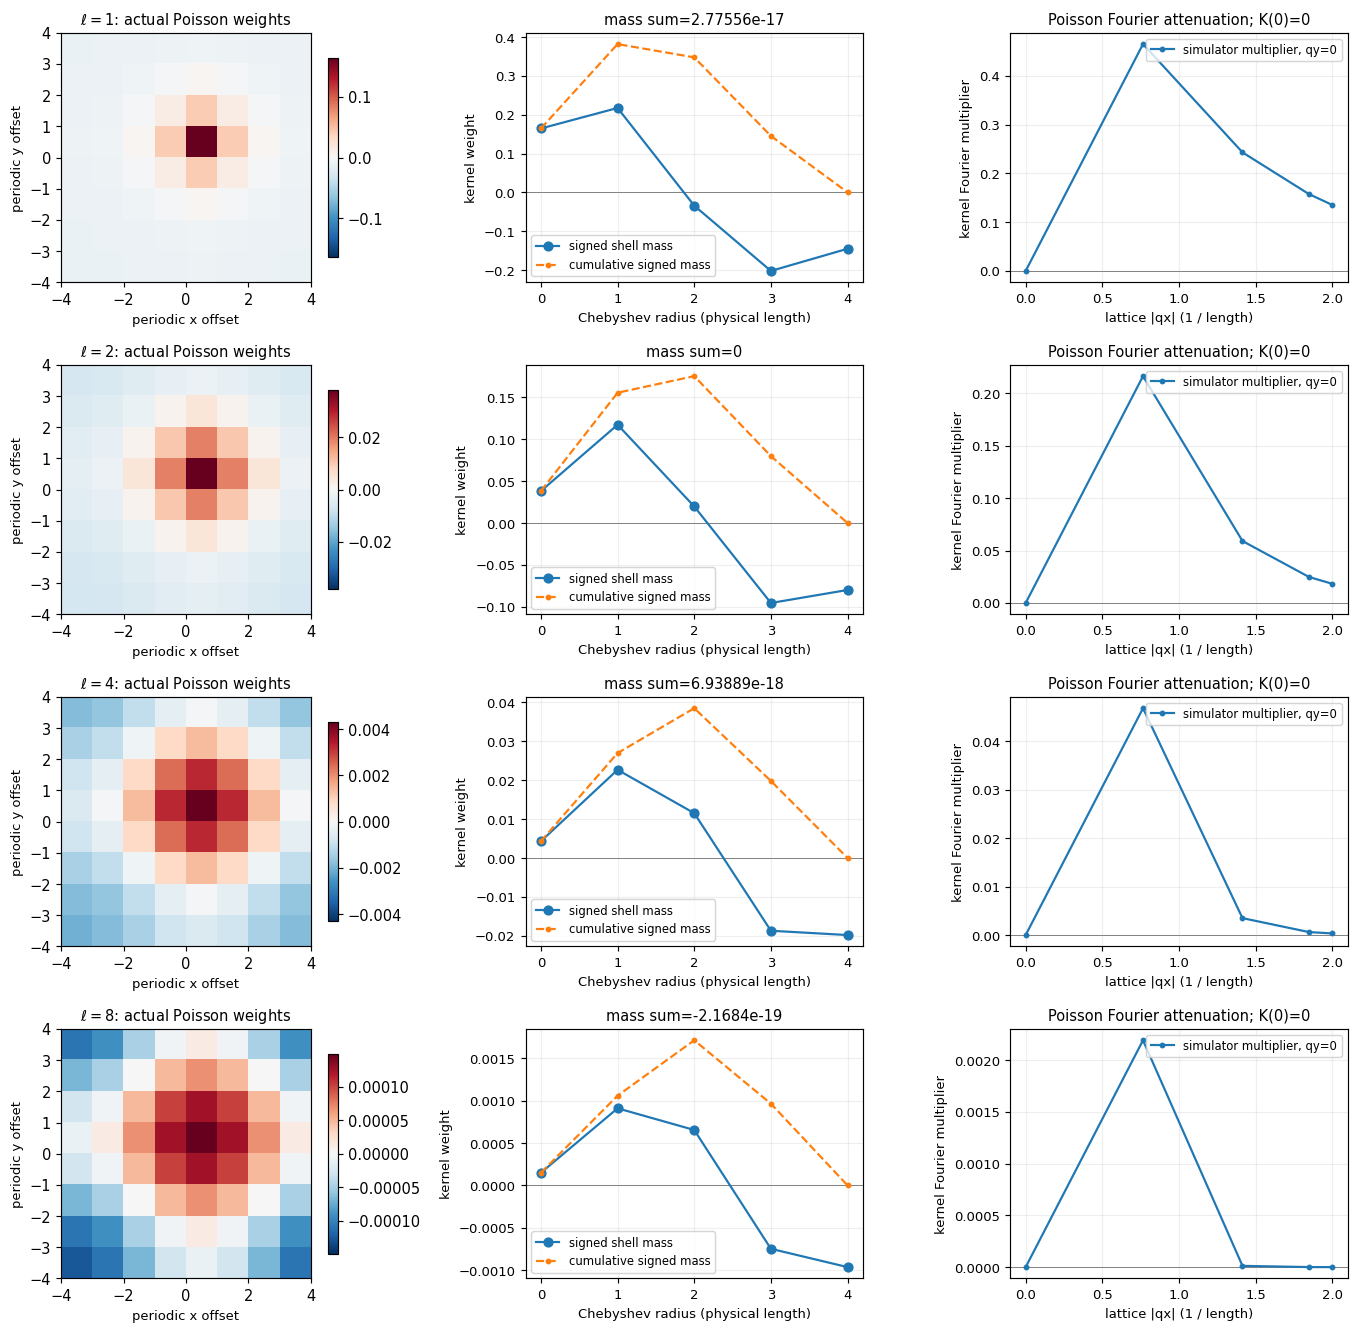

In [8]:
fig = plot_kernel_diagnostics(records)
plt.show()


## Cumulative EP

매 test trajectory 시작에서 누적합을 0으로 재설정한 뒤 독립 trajectory와 학습 seed를 평균한다. 서로 다른 trajectory를 이어 붙이지 않는다. reference의 conservative kernel EP는 quadratic energy 변화 \(-\Delta F_K/D\)로 정확히 telescoping하므로 장시간 평균에서 boundary 성격을 갖는다. local quartic term에는 solver의 midpoint quadrature 오차가 있을 수 있다. 우측은 medium reference를 local conservative / kernel conservative / active로 나눈 것이다.


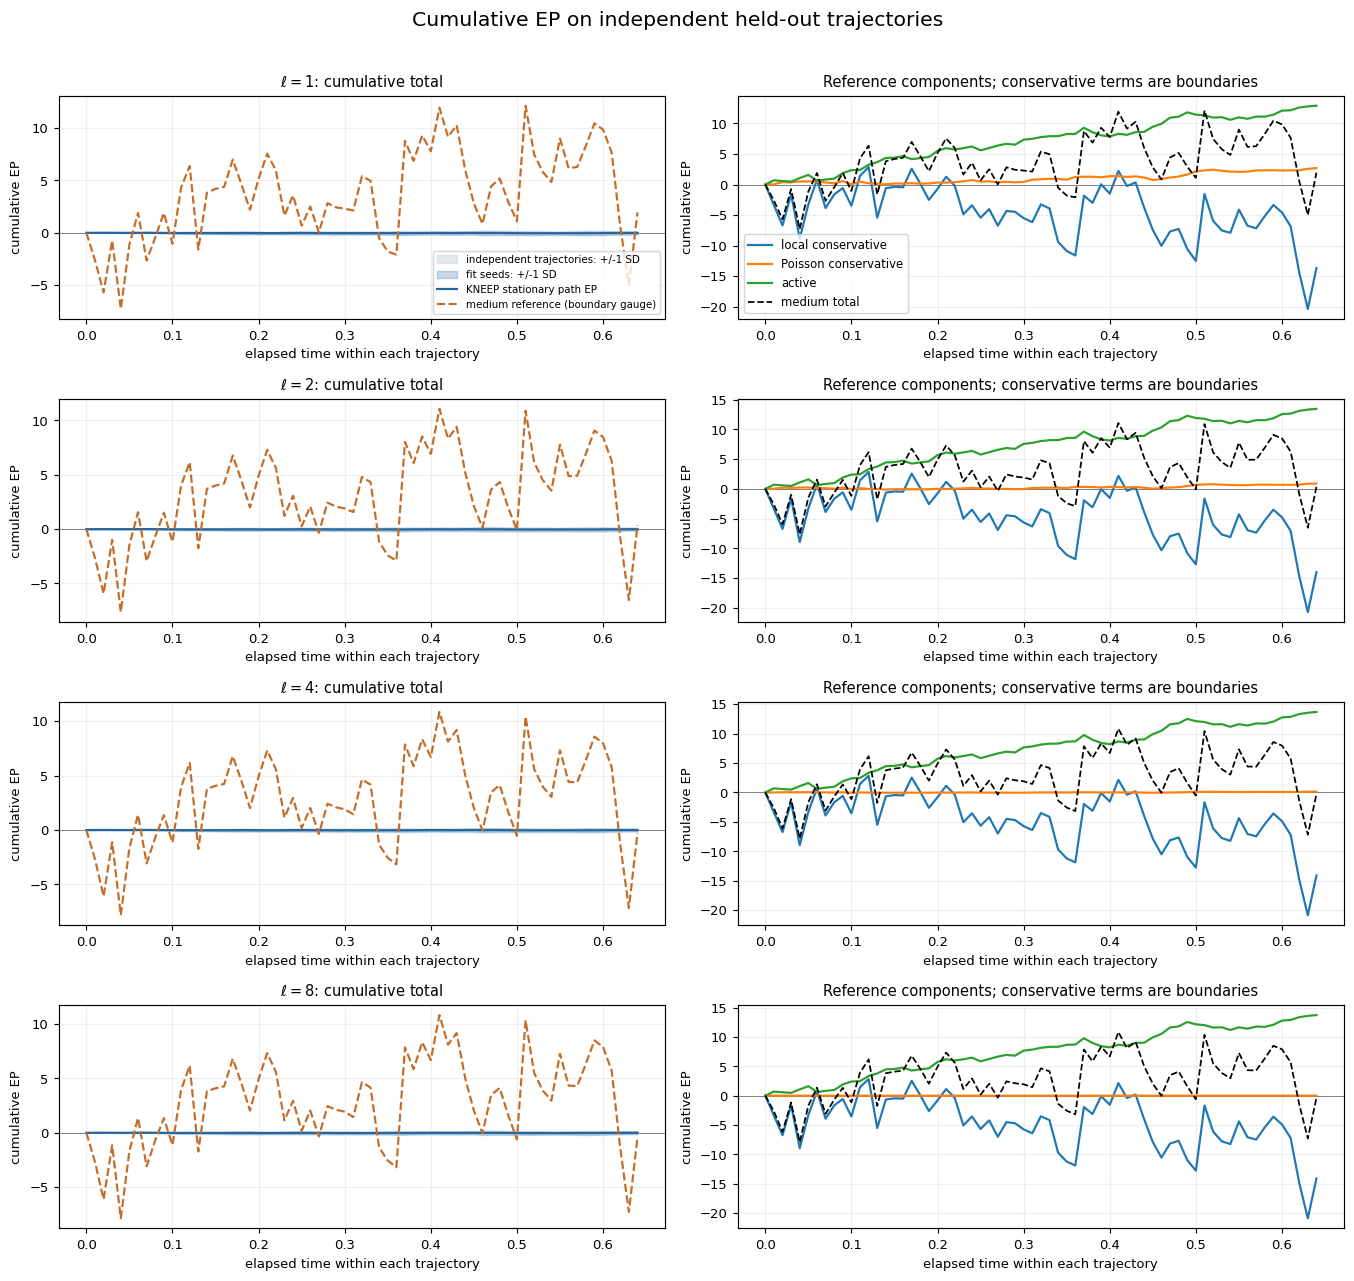

In [9]:
fig = plot_cumulative_ep(records)
plt.show()


## Time-averaged EP map

동일 번호의 독립 test trajectory 하나를 골라 모든 production interval을 평균한다. 첫 열은 최종 field, 둘째는 학습 seed 평균 learned map, 셋째는 medium reference map, 마지막은 학습 seed 간 map 표준편차이다. learned와 reference의 색 범위는 gauge별로 따로 정하며, 같은 열에서는 모든 ell 조건에 고정한다. 각 colorbar의 수치와 단위를 함께 읽는다. 각 map의 공간 합은 해당 global mean rate이다. 경계 gauge와 force 분해가 다르므로 site별 일치나 차이의 0을 목표로 삼지 않는다.


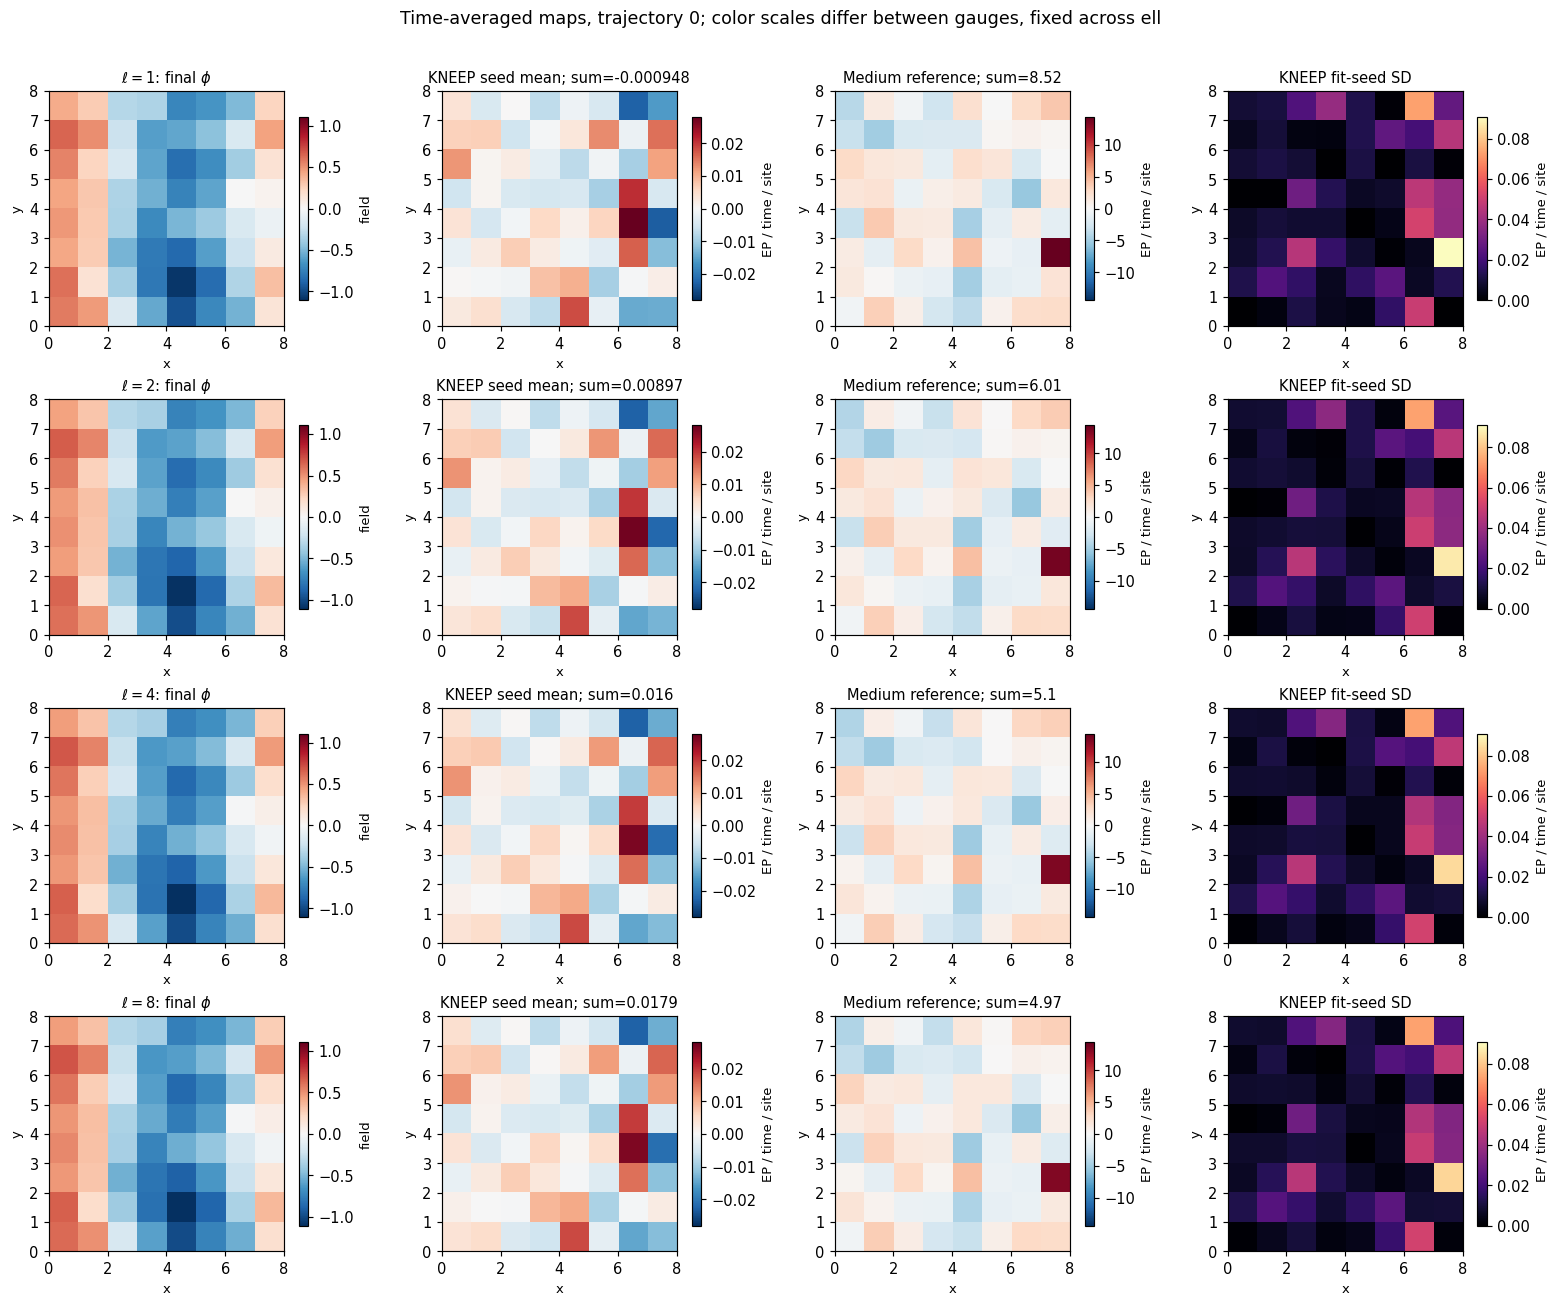

In [10]:
TEST_TRAJECTORY = 0
fig = plot_time_averaged_ep(records, trajectory=TEST_TRAJECTORY)
plt.show()


## EP spectrum과 variation — 공간 shell

여기서 EP spectrum은 branch / source-distance shell에 따른 signed EP rate 분해다. temporal frequency spectrum은 다음 cell에서 별도로 본다.

- 왼쪽: shell별 signed mean EP rate. 오차막대는 독립 trajectory SD와 학습 seed SD를 구분한다.
- 가운데: 각 trajectory 내부의 temporal variance를 먼저 계산한 뒤 평균한 값. 기준 관측 간격이 같아야 비교 가능하다.
- 오른쪽: 반경 이하 shell의 **signed** mean rate 누적합.

학습 branch 기여는 force의 좌표와 분배에 의존한다. 물리적 Poisson kernel shell의 exact decomposition과 동일하지 않으며, 개별 branch에는 학습 reference target이 없다. 중간의 shell variance를 단순히 더해 global variance를 얻으면 shell 간 covariance가 빠진다.


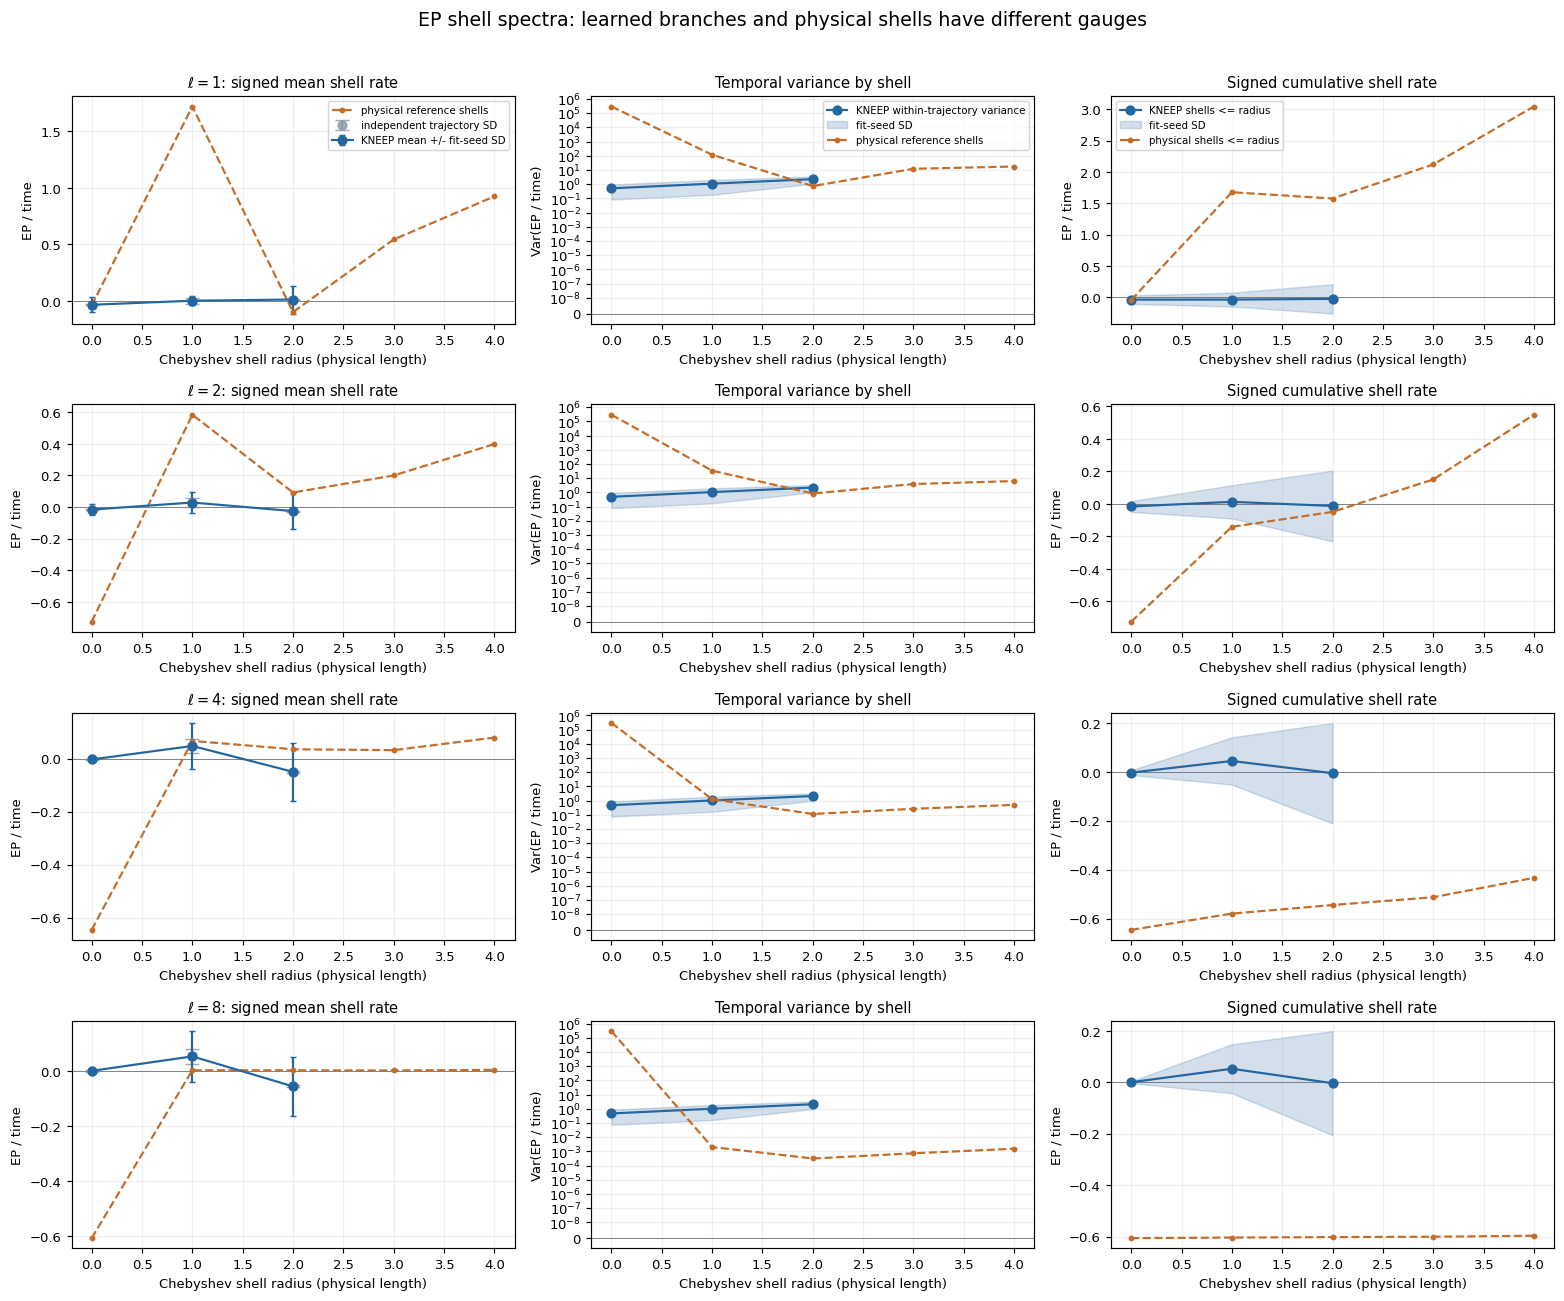

In [11]:
fig = plot_ep_spectrum(records)
plt.show()


## Temporal EP spectrum과 global variation

각 trajectory마다 branch를 **먼저 signed 합산**해 global rate를 구한다. 그 결과에서 temporal variance와 one-sided periodogram PSD를 계산하므로 cross-shell covariance를 보존한다. PSD는 각 trajectory의 시간 평균을 따로 제거한 뒤 계산하고, 그 power를 trajectory/seed에 대해 평균한다. trajectory를 이어 붙여 생기는 가짜 boundary jump는 포함하지 않는다.

PSD의 음영은 fit-seed SD다. 별도 trajectory SD와 confidence interval은 다른 개념이다. 이 그림의 간단한 periodogram은 긴 상관시간의 불확실성을 해결하지 않으므로, 정밀한 추정에는 trajectory 수 증가와 temporal block/bootstrap 또는 Welch 설정 비교가 필요하다.


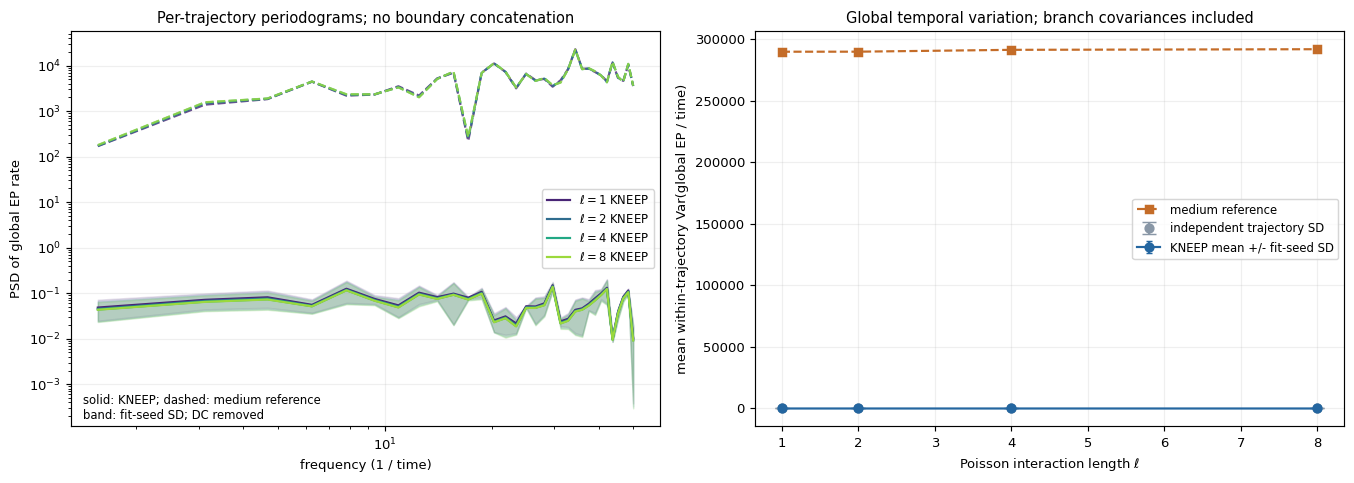

In [12]:
fig = plot_temporal_spectrum(records)
plt.show()


## Interaction range에 대한 반응 요약

global mean EP, 실제 signed kernel의 절댓값 tail, learned branch의 절댓값 signed-mean 기여 tail을 함께 본다. 마지막 tail은 \(|\langle \dot S_r\rangle|\)를 정규화한 **서술적 지표**이다. branch 식별 가능성이나 물리적 force range의 정답으로 해석하지 않는다. \(\ell\)이 커질수록 EP나 learned tail이 반드시 증가해야 한다는 판정 조건은 없다.


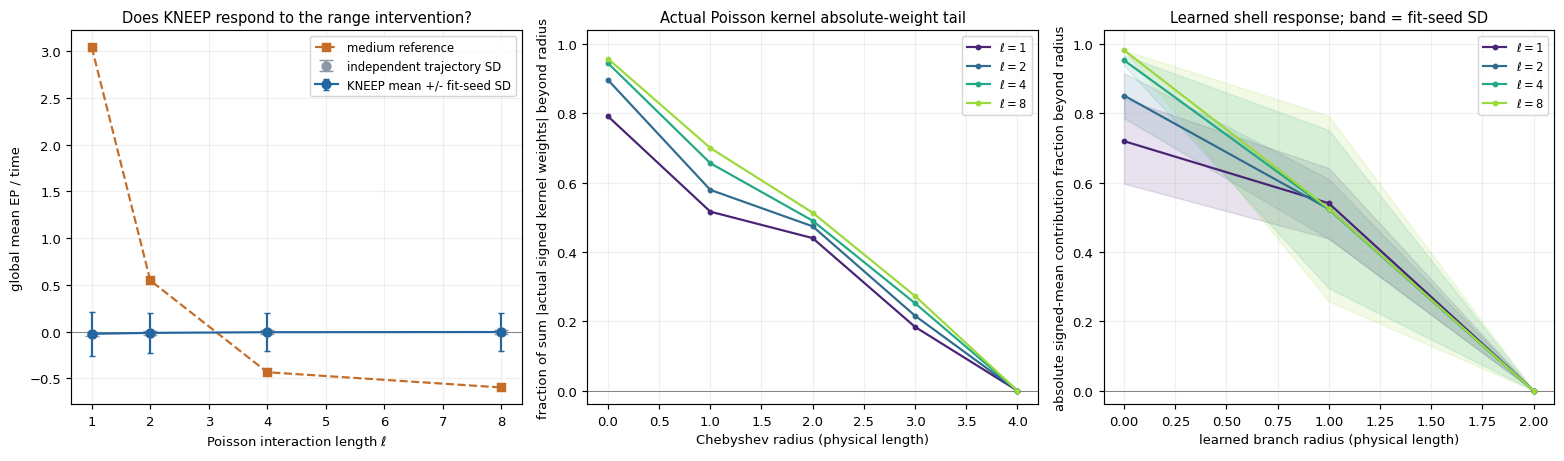

| ell | learned mean EP / time | fit-seed SD | independent trajectory SD | medium mean EP / time |
|---:|---:|---:|---:|---:|
| 1 | -0.0228904 | 0.233 | 0.0219 | 3.04291 |
| 2 | -0.0128994 | 0.217 | 0.0219 | 0.54809 |
| 4 | -0.00578601 | 0.206 | 0.0217 | -0.433828 |
| 8 | -0.00381764 | 0.202 | 0.0217 | -0.596766 |

In [13]:
fig = plot_range_response(records)
plt.show()

rows = ["| ell | learned mean EP / time | fit-seed SD | independent trajectory SD | medium mean EP / time |",
        "|---:|---:|---:|---:|---:|"]
for record in records:
    rates = record["predicted_increment"].sum(-1).mean(-1) / record["interval"]
    medium = record["reference_increment"].sum(-1).mean() / record["interval"]
    rows.append(f"| {record['ell']:g} | {rates.mean():.6g} | {rates.mean(1).std():.3g} | "
                f"{rates.mean(0).std():.3g} | {medium:.6g} |")
display(Markdown("\n".join(rows)))


## 결과를 판단할 때와 확장 실험

먼저 quarter drift, 학습/validation loss, seed spread를 확인한다. `quick`의 4 iterations와 짧은 burn-in은 코드 검증용이며, 그림에 나타난 변화는 수렴한 물리 결과를 뜻하지 않는다. demo/reference도 자동으로 stationarity나 모델 수렴을 보장하지 않는다.

1. **학습 수렴:** 동일 데이터에서 iterations / hidden channels / repeats를 늘리고 별도 결과 폴더에 저장한다.
2. **관측 간격:** 같은 \(dt\), burn/production 물리시간에서 `sample_every=1`로 데이터셋을 **새로 생성**해 학습한다. sparse frame을 보간해서 대체하지 않는다. 관측 사이에 숨은 EP와 paired estimator의 변화를 분리해 본다.
3. **수치 시간 간격:** \(dt\)를 줄이는 경우 burn_steps / production_steps / sample_every를 함께 조정해 물리시간과 관측 간격을 유지한다.
4. **유한 크기와 수용 범위:** \(\ell=8\)에 대해 격자와 모델 radius가 충분한지 더 큰 \(n\), 더 큰 학습 radius로 확인한다. 항상 `max_distance < n/2`를 지킨다.
5. **반복 실험:** base seed를 바꿔 train / val / test 전체를 새로 생성한다. 같은 데이터에서 fit seed만 바꾸는 것보다 강한 재현성 확인이다. \(\ell\) 사이 common-noise pairing은 보존한다.

예시 사용자 설정(별도 폴더에서 실행):
```python
fine_data = replace(DATA_CONFIG, sample_every=1)
fine_output = OUTPUT_DIR.parent / f"{PROFILE}_sample_every_1"
generate_datasets(fine_data, fine_output, lramb_root=LRAMB_ROOT, device=DATA_DEVICE)
train_sweep(fine_output, FIT_CONFIG, device=FIT_DEVICE)
fine_records = evaluate_sweep(fine_output, device=FIT_DEVICE)
fig = plot_cumulative_ep(fine_records)
plt.show()
```
